# XGBoost

Test Set Accuracy: 0.9122
Classification Report:
              precision    recall  f1-score   support

        five       0.89      0.90      0.89       222
        four       0.88      0.89      0.89       294
         one       0.99      1.00      0.99       219
       three       0.84      0.73      0.78        84
         two       0.94      0.95      0.94       149

    accuracy                           0.91       968
   macro avg       0.91      0.89      0.90       968
weighted avg       0.91      0.91      0.91       968



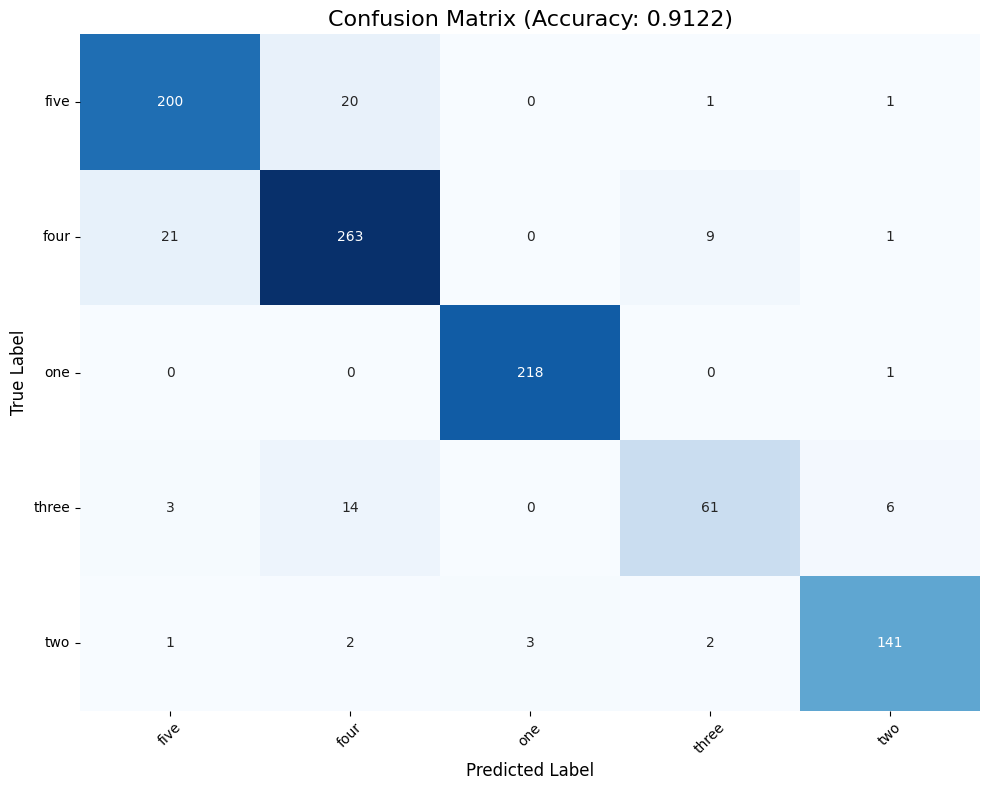

<Figure size 1200x800 with 0 Axes>

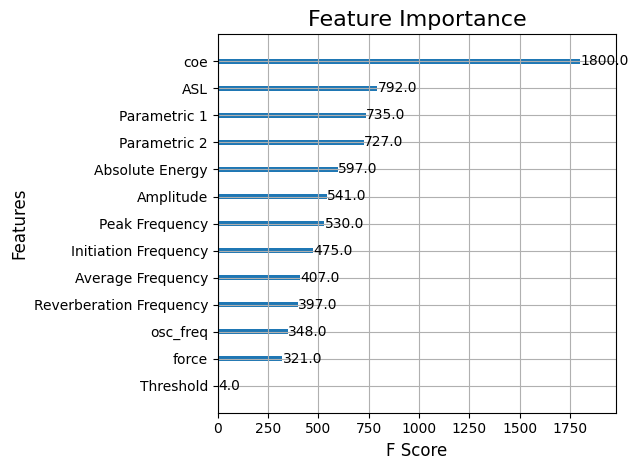

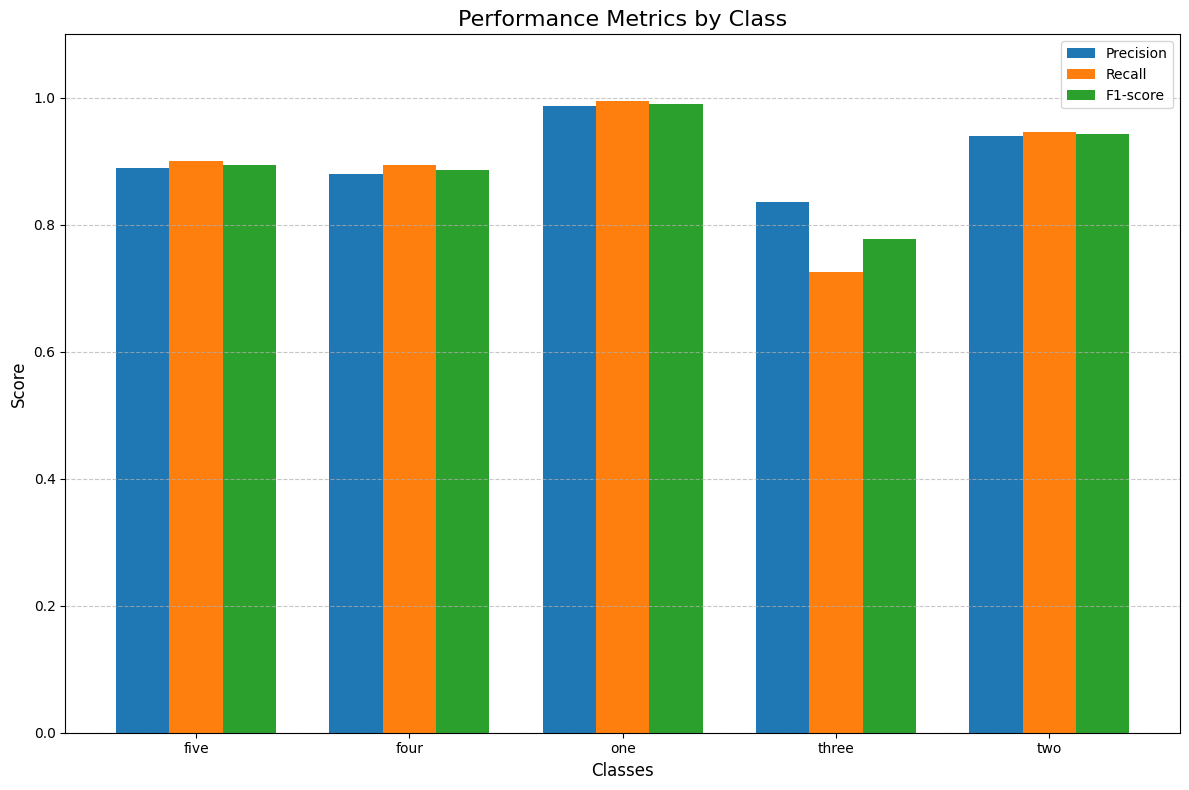

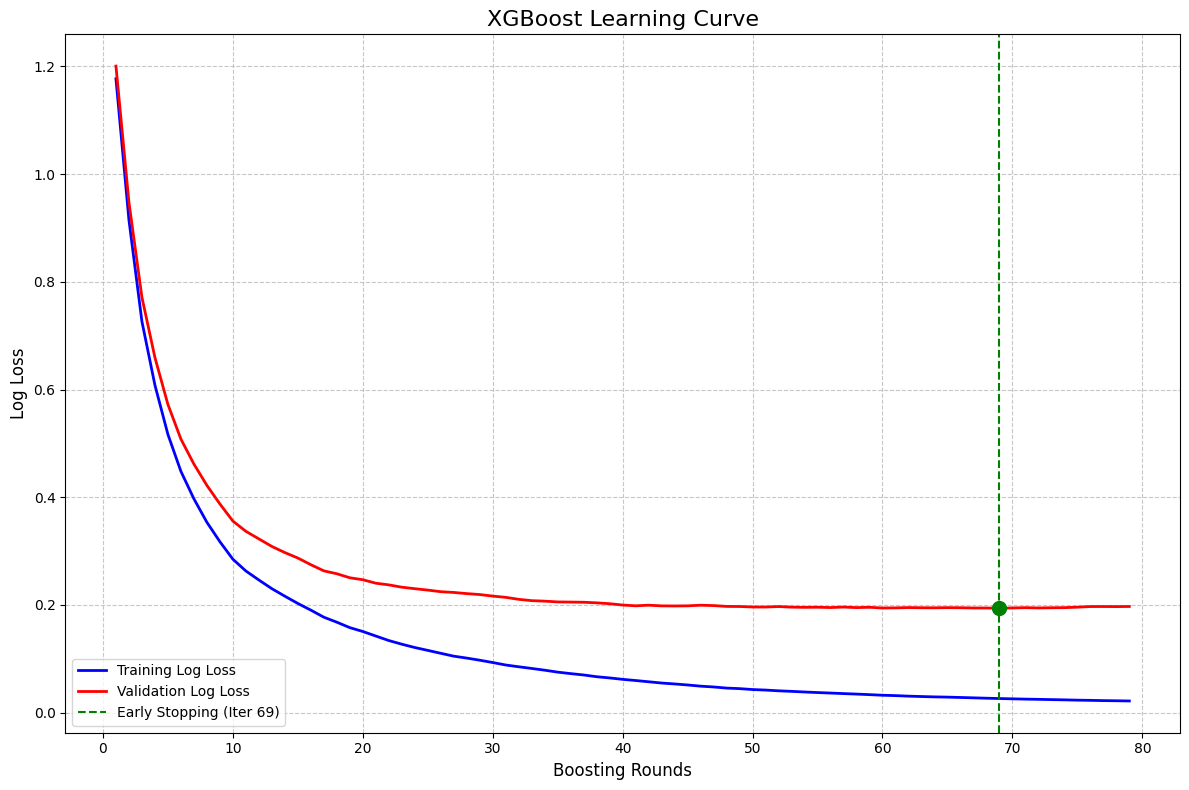

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 加载数据
df = pd.read_csv(r'D:\STUDY\internship\code_internship\dataset\sensor\data_prepared.csv')

# 2. 数据预处理
X = df.drop(columns=['material', 'stroke', 'stage', 'cycle'])
y = df['stage']

# 3. 编码标签
le = LabelEncoder()
y_encoded = le.fit_transform(y)
class_names = le.classes_

# 4. 划分数据集
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 5. create DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

# 6. parameters of XGBoost
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 6,
    'eta': 0.3,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'eval_metric': 'mlogloss',
    'seed': 42
}

# 7. 训练模型并捕获评估结果
evals_result = {}
num_round = 100
model = xgb.train(params, dtrain, num_round, 
                 evals=[(dtrain, 'train'), (dtest, 'eval')], 
                 early_stopping_rounds=10,
                 evals_result=evals_result,
                 verbose_eval=False)

# 8. 模型评估
y_pred = model.predict(dtest)
accuracy = accuracy_score(y_test, y_pred)

# 直接输出分类报告（文字形式）
print("=" * 70)
print(f"Test Set Accuracy: {accuracy:.4f}")
print("=" * 70)
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))
print("=" * 70)

# 9. 单独绘制混淆矩阵
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            cbar=False)
plt.title(f'Confusion Matrix (Accuracy: {accuracy:.4f})', fontsize=16)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 10. 单独绘制特征重要性
plt.figure(figsize=(12, 8))
xgb.plot_importance(model, max_num_features=20, importance_type='weight')
plt.title('Feature Importance', fontsize=16)
plt.xlabel('F Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

# 11. 单独绘制各类别性能对比
report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
metrics = ['precision', 'recall', 'f1-score']

plt.figure(figsize=(12, 8))
x = np.arange(len(class_names))
width = 0.25

for i, metric in enumerate(metrics):
    plt.bar(x + i*width, [report[cls][metric] for cls in class_names], 
            width=width, label=metric.capitalize())

plt.title('Performance Metrics by Class', fontsize=16)
plt.xlabel('Classes', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.xticks(x + width, class_names)
plt.ylim(0, 1.1)
plt.legend(loc='best', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 12. 学习曲线可视化
if 'train' in evals_result and 'eval' in evals_result:
    train_errors = evals_result['train']['mlogloss']
    eval_errors = evals_result['eval']['mlogloss']
    
    epochs = range(1, len(train_errors) + 1)
    
    plt.figure(figsize=(12, 8))
    plt.plot(epochs, train_errors, 'b-', label='Training Log Loss', linewidth=2)
    plt.plot(epochs, eval_errors, 'r-', label='Validation Log Loss', linewidth=2)
    
    # 标记提前停止点
    if model.attr('best_iteration') is not None:
        best_iter = int(model.attr('best_iteration'))
        best_score = eval_errors[best_iter]
        plt.axvline(x=best_iter+1, color='g', linestyle='--', 
                   label=f'Early Stopping (Iter {best_iter+1})')
        plt.scatter(best_iter+1, best_score, s=100, c='g', zorder=5)
    
    plt.title('XGBoost Learning Curve', fontsize=16)
    plt.xlabel('Boosting Rounds', fontsize=12)
    plt.ylabel('Log Loss', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
else:
    print("Warning: Evaluation results not available for learning curve")